## Loading The Raw Data And Inspecting What It Contains

In [1]:
import duckdb
import pandas as pd

con = duckdb.connect()
#saving our file paths into a dictionary
files = {

    "branches": "../data/raw/branches.parquet",
    "customers": "../data/raw/customers.parquet",
    "accounts": "../data/raw/accounts.parquet",
    "merchants": "../data/raw/merchants.parquet",
    "transactions": "../data/raw/transactions.parquet"
}

#loading all of out dataset's tables
transactions = con.execute(
    f"SELECT * FROM read_parquet('{files['transactions']}' )"
).df()
branches = con.execute(
    f"SELECT * FROM read_parquet('{files['branches']}')"
).df()

customers = con.execute(
    f"SELECT * FROM read_parquet('{files['customers']}')"
).df()

accounts = con.execute(
    f"SELECT * FROM read_parquet('{files['accounts']}')"
).df()

merchants = con.execute(
    f"SELECT * FROM read_parquet('{files['merchants']}')"
).df()

In [2]:
#checking wether all the content of our tables are loaded correctly
print(branches.shape)
print(customers.shape)
print(accounts.shape)
print(merchants.shape)
print(transactions.shape)

(40, 5)
(9000, 9)
(14000, 7)
(800, 4)
(320000, 9)


## 1. Data Exploration & Feature Engineering
### What does the transaction distribution look like?
* What is a typical transaction amount?
* How spread out are transaction values?
* Are there extreme values?

In [3]:
transactions.head()

,transaction_id,account_id,merchant_id,posted_at,transaction_type,direction,amount,channel,description
0,1,20,<NA>,2025-12-25 17:41:42,salary,credit,1440.00,card,SALARY
1,2,13277,280,2025-03-27 12:11:54,refund,credit,30.92,mobile,VECTOR FITNESS
2,3,902,<NA>,2025-06-02 13:48:05,interest,credit,11.20,card,INTEREST
3,4,12417,448,2024-10-30 11:13:34,card_payment,debit,34.78,card,CEDAR ENERGY 2
4,5,468,104,2025-01-25 14:17:05,card_payment,debit,4.95,online,NORTH MEDIA


In [4]:
print (transactions["amount"].mean())
print (transactions["amount"].median())

201.9224498125
28.02


In [5]:
print(transactions["amount"].std())
print(transactions["amount"].quantile([0.25, 0.5, 0.75, 0.95, 0.99]))

694.8970260414696
0.25      12.81
0.50      28.02
0.75      63.95
0.95    1540.00
0.99    3710.00
Name: amount, dtype: float64


In [6]:
print (transactions["amount"].min())
print (transactions["amount"].max())

0.17
12880.0


### When do transactions happen?

* Which months have the most activity?
* Which days of the week are busiest?
* Which hours have the most transactions?
* signed transaction amount

In [7]:
transactions["month"] = transactions["posted_at"].dt.to_period("M")
transactions["year"] = transactions["posted_at"].dt.year
transactions["day_of_week"] = transactions["posted_at"].dt.day_name()
transactions["hour"] = transactions["posted_at"].dt.hour

In [8]:
transactions.head()

,transaction_id,account_id,merchant_id,posted_at,transaction_type,direction,amount,channel,description,month,year,day_of_week,hour
0,1,20,<NA>,2025-12-25 17:41:42,salary,credit,1440.00,card,SALARY,2025-12,2025,Thursday,17
1,2,13277,280,2025-03-27 12:11:54,refund,credit,30.92,mobile,VECTOR FITNESS,2025-03,2025,Thursday,12
2,3,902,<NA>,2025-06-02 13:48:05,interest,credit,11.20,card,INTEREST,2025-06,2025,Monday,13
3,4,12417,448,2024-10-30 11:13:34,card_payment,debit,34.78,card,CEDAR ENERGY 2,2024-10,2024,Wednesday,11
4,5,468,104,2025-01-25 14:17:05,card_payment,debit,4.95,online,NORTH MEDIA,2025-01,2025,Saturday,14


In [9]:
#activity_per_month
transactions["month"].value_counts(ascending=False).sort_index()


month
2024-01    12830
2024-02    11977
2024-03    12830
2024-04    12509
2024-05    12716
2024-06    12725
2024-07    12841
2024-08    13004
2024-09    12465
2024-10    12911
2024-11    14792
2024-12    18296
2025-01    13131
2025-02    11629
2025-03    13083
2025-04    12342
2025-05    13000
2025-06    12541
2025-07    12641
2025-08    12961
2025-09    12463
2025-10    12770
2025-11    15238
2025-12    18305
Freq: M, Name: count, dtype: int64

In [10]:
#activity_per_day_of_week
transactions["day_of_week"].value_counts(ascending=False).sort_index()


day_of_week
Friday       43480
Monday       43848
Saturday     50461
Sunday       50274
Thursday     43585
Tuesday      44414
Wednesday    43938
Name: count, dtype: int64

In [11]:
#activity_per_hour
transactions["hour"].value_counts(ascending=False).sort_index()

hour
0      4704
1      4838
2      4762
3      4764
4      4762
5      4801
6      4832
7      4850
8     19229
9     19424
10    19729
11    19489
12    19720
13    19267
14    19353
15    19305
16    19550
17    19260
18    19460
19    19280
20    19439
21    19493
22     4900
23     4789
Name: count, dtype: int64

In [12]:
import numpy as np

In [13]:
transactions["signed_amount"] = np.where(transactions["direction"] == "credit", transactions["amount"], -transactions["amount"])

In [14]:
transactions[
    [
        "posted_at",
        "direction",
        "amount",
        "signed_amount",
        "month",
        "year",
        "day_of_week",
        "hour"
    ]
].head()

,posted_at,direction,amount,signed_amount,month,year,day_of_week,hour
0,2025-12-25 17:41:42,credit,1440.00,1440.00,2025-12,2025,Thursday,17
1,2025-03-27 12:11:54,credit,30.92,30.92,2025-03,2025,Thursday,12
2,2025-06-02 13:48:05,credit,11.20,11.20,2025-06,2025,Monday,13
3,2024-10-30 11:13:34,debit,34.78,-34.78,2024-10,2024,Wednesday,11
4,2025-01-25 14:17:05,debit,4.95,-4.95,2025-01,2025,Saturday,14


## Customer Behaviour Analysis

### How does transaction behaviour differ between customers?
* Which customers make the most transactions?
* Which have the highest transaction value?
* What does the distribution of customer activity look like?

In [15]:
#Merging the customer and the transactions tables to perform our analysis
customer_transactions = customers.merge(

    accounts,

    on="customer_id"

)
customer_transactions = customer_transactions.merge(

    transactions,

    on="account_id"

)
customer_transactions.head()

,customer_id,first_name,last_name,email,city,country,home_branch_id,joined_on,risk_band,account_id,...,transaction_type,direction,amount,channel,description,month,year,day_of_week,hour,signed_amount
0,1,Andres,Bauer,andres.bauer0@example.com,Valencia,ES,3,2009-01-19,NaN,1,...,interest,credit,18.61,branch,INTEREST,2024-09,2024,Sunday,21,18.61
1,1,Andres,Bauer,andres.bauer0@example.com,Valencia,ES,3,2009-01-19,NaN,1,...,transfer_out,debit,14.82,card,TRANSFER OUT,2024-08,2024,Thursday,15,-14.82
2,1,Andres,Bauer,andres.bauer0@example.com,Valencia,ES,3,2009-01-19,NaN,1,...,card_payment,debit,13.92,card,BLUE SUPPLY,2024-05,2024,Monday,20,-13.92
3,1,Andres,Bauer,andres.bauer0@example.com,Valencia,ES,3,2009-01-19,NaN,1,...,interest,credit,5.83,mobile,INTEREST,2024-07,2024,Sunday,10,5.83
4,1,Andres,Bauer,andres.bauer0@example.com,Valencia,ES,3,2009-01-19,NaN,1,...,card_payment,debit,116.31,mobile,KESTREL BOOKS 2,2025-06,2025,Friday,9,-116.31


In [16]:
#customers with the most amount of transactions ranked
customer_transactions.groupby(["customer_id", "first_name", "last_name"])["transaction_id"].count().sort_values(ascending=False).head(15)


customer_id  first_name  last_name
1            Andres      Bauer        54637
2            Raj         Quinn        21604
3            Kwame       Adeyemi      14829
4            Claire      Frost         9603
5            Sofia       Haddad        6097
6            Noel        Abbott        5564
6573         Tarek       Hale          4876
9            Viktor      Tan           4749
8            Nadia       Ashworth      4233
7            Emeka       Beaumont      4169
11           Tomas       Park          3706
435          Amara       Nair          3604
10           Aoife       Whitfield     3365
13           Tomas       Kaur          2904
15           Marta       Novak         2594
Name: transaction_id, dtype: int64

In [17]:
#customers with the most value of transactions ranked
customer_transactions.groupby(["customer_id", "first_name", "last_name"])["amount"].sum().sort_values(ascending=False).head(15)

customer_id  first_name  last_name
1            Andres      Bauer        11024514.17
2            Raj         Quinn         4352985.75
3            Kwame       Adeyemi       2958685.07
4            Claire      Frost         2005745.13
5            Sofia       Haddad        1354853.03
6            Noel        Abbott        1072062.75
6573         Tarek       Hale           946576.95
9            Viktor      Tan            930944.01
8            Nadia       Ashworth       855121.92
7            Emeka       Beaumont       810129.80
435          Amara       Nair           702707.46
10           Aoife       Whitfield      693419.14
11           Tomas       Park           684374.47
13           Tomas       Kaur           601690.11
27           Kofi        Marchetti      522962.21
Name: amount, dtype: float64

In [18]:
customer_transaction_value = (
    customer_transactions
    .groupby(["customer_id", "first_name", "last_name"])["amount"]
    .sum()
    .rename("transactions_value")
    .reset_index()
)
customer_transaction_value.head()

,customer_id,first_name,last_name,transactions_value
0,1,Andres,Bauer,11024514.17
1,2,Raj,Quinn,4352985.75
2,3,Kwame,Adeyemi,2958685.07
3,4,Claire,Frost,2005745.13
4,5,Sofia,Haddad,1354853.03


In [19]:
customer_transaction_value["transactions_value"].quantile(
    [0.25, 0.50, 0.75, 0.95, 0.99]
)

0.25       688.0450
0.50      3866.1700
0.75      9872.1625
0.95     58914.1010
0.99    291847.0170
Name: transactions_value, dtype: float64

### Which customers are statistical outliers?
* Which customers have unusually high activity?
* Which have unusually high transaction values?
* Which have unusually low activity?

In [20]:
customer_transaction_value = (
    customer_transactions.groupby(["customer_id", "first_name", "last_name"])
    .agg(
        transactions_value =("amount", "sum"),
        transactions_volume=("transaction_id", "count")
    ).reset_index()
)
customer_transaction_value.head()

,customer_id,first_name,last_name,transactions_value,transactions_volume
0,1,Andres,Bauer,11024514.17,54637
1,2,Raj,Quinn,4352985.75,21604
2,3,Kwame,Adeyemi,2958685.07,14829
3,4,Claire,Frost,2005745.13,9603
4,5,Sofia,Haddad,1354853.03,6097


In [21]:
customer_transaction_value_mean = customer_transaction_value["transactions_value"].mean()
customer_transaction_value_std = customer_transaction_value["transactions_value"].std()
customer_transaction_volume_mean = customer_transaction_value["transactions_volume"].mean()
customer_transaction_volume_std = customer_transaction_value["transactions_volume"].std()

In [22]:
customer_transaction_behaviour = customer_transaction_value.copy()

In [23]:
value_z = (customer_transaction_behaviour["transactions_value"] - customer_transaction_value_mean)/customer_transaction_value_std
volume_z = (customer_transaction_behaviour["transactions_volume"] - customer_transaction_volume_mean)/customer_transaction_volume_std

In [24]:
customer_transaction_behaviour["customer_transaction_value_behaviour"] = np.select(
    [
        value_z < -3,
        value_z < -2,
        value_z < 2,
        value_z < 3,
        value_z >= 3
    ],
    [
        "Very Unusually Low - Outlier",
        "Unusually Low",
        "Normal",
        "Unusually High",
        "Very Unusually High - Outlier"
    ],
    default= "null"
)
customer_transaction_behaviour["customer_transaction_volume_behaviour"] = np.select(
    [
        volume_z < -3,
        volume_z < -2,
        volume_z < 2,
        volume_z < 3,
        volume_z >= 3
    ],
    [
        "Very Unusually Low - Potential Outlier",
        "Unusually Low",
        "Normal",
        "Unusually High",
        "Very Unusually High - Potential Outlier"
    ],
    default="null"
)

In [25]:
customer_transaction_behaviour.head()

,customer_id,first_name,last_name,transactions_value,transactions_volume,customer_transaction_value_behaviour,customer_transaction_volume_behaviour
0,1,Andres,Bauer,11024514.17,54637,Very Unusually High - Outlier,Very Unusually High - Potential Outlier
1,2,Raj,Quinn,4352985.75,21604,Very Unusually High - Outlier,Very Unusually High - Potential Outlier
2,3,Kwame,Adeyemi,2958685.07,14829,Very Unusually High - Outlier,Very Unusually High - Potential Outlier
3,4,Claire,Frost,2005745.13,9603,Very Unusually High - Outlier,Very Unusually High - Potential Outlier
4,5,Sofia,Haddad,1354853.03,6097,Very Unusually High - Outlier,Very Unusually High - Potential Outlier


## Account Analysis


## Which account types behave differently?

* Transaction volume
* Transaction value
* Average transaction size

In [26]:
accounts.head()

,account_id,customer_id,account_type,currency,opened_on,closed_on,overdraft_limit
0,1,1,current,GBP,2024-11-28,NaT,0.0
1,2,6573,savings,USD,2024-10-03,NaT,0.0
2,3,435,credit_card,GBP,2025-09-11,NaT,0.0
3,4,1,loan,GBP,2024-01-27,NaT,0.0
4,5,1047,current,GBP,2024-04-18,NaT,1000.0


In [27]:
account_transactions = accounts.merge(
    transactions,
    on= "account_id"
)
account_transactions.head()

,account_id,customer_id,account_type,currency,opened_on,closed_on,overdraft_limit,transaction_id,merchant_id,posted_at,transaction_type,direction,amount,channel,description,month,year,day_of_week,hour,signed_amount
0,1,1,current,GBP,2024-11-28,NaT,0.0,36,<NA>,2024-09-29 21:33:25,interest,credit,18.61,branch,INTEREST,2024-09,2024,Sunday,21,18.61
1,1,1,current,GBP,2024-11-28,NaT,0.0,77,<NA>,2024-08-01 15:54:32,transfer_out,debit,14.82,card,TRANSFER OUT,2024-08,2024,Thursday,15,-14.82
2,1,1,current,GBP,2024-11-28,NaT,0.0,111,21,2024-05-20 20:01:23,card_payment,debit,13.92,card,BLUE SUPPLY,2024-05,2024,Monday,20,-13.92
3,1,1,current,GBP,2024-11-28,NaT,0.0,177,<NA>,2024-07-28 10:55:17,interest,credit,5.83,mobile,INTEREST,2024-07,2024,Sunday,10,5.83
4,1,1,current,GBP,2024-11-28,NaT,0.0,241,692,2025-06-20 09:04:43,card_payment,debit,116.31,mobile,KESTREL BOOKS 2,2025-06,2025,Friday,9,-116.31


In [28]:
account_type_behaviour = (
    account_transactions
    .groupby("account_type")
    .agg(
        transactions_value=("amount", "sum"),
        transactions_volume=("transaction_id", "count"),
        average_transaction_size=("amount", "mean")
    )
    .reset_index()
)
account_type_behaviour.head()

,account_type,transactions_value,transactions_volume,average_transaction_size
0,credit_card,8879029.47,43648,203.423512
1,current,31075966.02,153937,201.874572
2,loan,4536748.43,22723,199.654466
3,savings,20123440.02,99692,201.856117


## Which individual accounts are unusually active?

* Transaction count distribution
* High-activity accounts
* Low-activity accounts

In [29]:
account_transactions_volume = (
    account_transactions
    .groupby(["account_id", "customer_id"])
    .agg(
        transactions_volume=("transaction_id", "count")
    )
    .reset_index()
)
account_transactions_volume.head()

,account_id,customer_id,transactions_volume
0,1,1,8114
1,2,6573,4870
2,3,435,3593
3,4,1,2890
4,5,1047,2413


In [30]:
account_z = (account_transactions_volume["transactions_volume"]- account_transactions_volume["transactions_volume"].mean()) / account_transactions_volume["transactions_volume"].std()

In [31]:
account_behaviour = account_transactions_volume.copy()
account_behaviour["account_transactions_behaviour"] =np.select(
    [
        account_z <= -3,
        account_z < -2,
        account_z <= 2,
        account_z < 3,
        account_z >= 3
    ],  
    [
        "Very Unusually Low - Outlier",
        "Unusually Low",
        "Normal",
        "Unusually High",
        "Very Unusually High - Outlier"
    ],
    default= "null"
)
account_behaviour.head()

,account_id,customer_id,transactions_volume,account_transactions_behaviour
0,1,1,8114,Very Unusually High - Outlier
1,2,6573,4870,Very Unusually High - Outlier
2,3,435,3593,Very Unusually High - Outlier
3,4,1,2890,Very Unusually High - Outlier
4,5,1047,2413,Very Unusually High - Outlier


In [32]:
account_behaviour["account_transactions_behaviour"].value_counts()

account_transactions_behaviour
Normal                           13890
Very Unusually High - Outlier       64
Unusually High                      42
Name: count, dtype: int64

## Time-Series Analysis

### How does transaction activity change over time?

* Monthly transaction count
* Monthly transaction value
* Debit vs credit over time

In [33]:
transactions.head()

,transaction_id,account_id,merchant_id,posted_at,transaction_type,direction,amount,channel,description,month,year,day_of_week,hour,signed_amount
0,1,20,<NA>,2025-12-25 17:41:42,salary,credit,1440.00,card,SALARY,2025-12,2025,Thursday,17,1440.00
1,2,13277,280,2025-03-27 12:11:54,refund,credit,30.92,mobile,VECTOR FITNESS,2025-03,2025,Thursday,12,30.92
2,3,902,<NA>,2025-06-02 13:48:05,interest,credit,11.20,card,INTEREST,2025-06,2025,Monday,13,11.20
3,4,12417,448,2024-10-30 11:13:34,card_payment,debit,34.78,card,CEDAR ENERGY 2,2024-10,2024,Wednesday,11,-34.78
4,5,468,104,2025-01-25 14:17:05,card_payment,debit,4.95,online,NORTH MEDIA,2025-01,2025,Saturday,14,-4.95


In [34]:
monthly_transactions = (
    transactions.groupby("month")
    .agg(
        transactions_value = ("amount", "sum"),
        transactions_volume = ("transaction_id", "count"),
        debit_count = ("direction", lambda x : (x=="debit").sum()),
        credit_count = ("direction", lambda x : (x=="credit").sum())
    ).reset_index()
)

monthly_transactions

,month,transactions_value,transactions_volume,debit_count,credit_count
0,2024-01,2590540.38,12830,10280,2550
1,2024-02,2453011.42,11977,9516,2461
2,2024-03,2807630.85,12830,10230,2600
3,2024-04,2517824.96,12509,10012,2497
4,2024-05,2474219.17,12716,10231,2485
5,2024-06,2471362.76,12725,10233,2492
6,2024-07,2578738.05,12841,10337,2504
7,2024-08,2621011.93,13004,10462,2542
8,2024-09,2551317.14,12465,10026,2439
9,2024-10,2650562.42,12911,10293,2618


### Are there seasonal patterns?

* Are certain months consistently busier?
* Are certain days of the week more active?
* Are there particular hours with unusually high activity?

In [35]:

months_transaction = monthly_transactions.copy()

# extracting month number and convert it to month name
months_transaction["month"] = (
    months_transaction["month"].dt.month.map(
        lambda x: pd.Timestamp(2000, x, 1).month_name()
    )
)

months_transaction = (
    months_transaction
    .groupby("month")
    .agg(
        transactions_volume=("transactions_volume", "sum")
    )
    .reset_index()
)
months_transaction

,month,transactions_volume
0,April,24851
1,August,25965
2,December,36601
3,February,23606
4,January,25961
5,July,25482
6,June,25266
7,March,25913
8,May,25716
9,November,30030


In [36]:
# we want them to show them buy the order of the months but python automatically orders them alphabetically therefore we will 
# define the order ourselves
months_order = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
months_transaction["month"] = pd.Categorical(
    months_transaction["month"],
    categories=months_order,
    ordered=True
)
months_transaction = months_transaction.sort_values("month")
months_transaction

,month,transactions_volume
4,January,25961
3,February,23606
7,March,25913
0,April,24851
8,May,25716
6,June,25266
5,July,25482
1,August,25965
11,September,24928
10,October,25681


In [37]:
daily_transactions = (
    transactions.groupby("day_of_week")
    .agg(
        transaction_volume = ("transaction_id", "count")
    ).reset_index()
    )
daily_transactions

,day_of_week,transaction_volume
0,Friday,43480
1,Monday,43848
2,Saturday,50461
3,Sunday,50274
4,Thursday,43585
5,Tuesday,44414
6,Wednesday,43938


In [38]:
days_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily_transactions["day_of_week"] = pd.Categorical(
    daily_transactions["day_of_week"],
    categories = days_order,
    ordered=True
)
daily_transactions = daily_transactions.sort_values("day_of_week")
daily_transactions

,day_of_week,transaction_volume
1,Monday,43848
5,Tuesday,44414
6,Wednesday,43938
4,Thursday,43585
0,Friday,43480
2,Saturday,50461
3,Sunday,50274


In [39]:
hourly_transactions = (
    transactions.groupby("hour")
    .agg(
        transaction_volume = ("transaction_id", "count")
    ).reset_index()
)
hourly_transactions

,hour,transaction_volume
0,0,4704
1,1,4838
2,2,4762
3,3,4764
4,4,4762
5,5,4801
6,6,4832
7,7,4850
8,8,19229
9,9,19424


### What are the trends in transaction value?

* monthly total
* monthly average
* month-over-month change
* rolling average

In [40]:
monthly_transactions = (
    transactions.groupby("month")
    .agg(
        total_transactions_value = ("amount", "sum"),
        transactions_average_value = ("amount", "mean")
    ).reset_index()
)
monthly_transactions

,month,total_transactions_value,transactions_average_value
0,2024-01,2590540.38,201.912734
1,2024-02,2453011.42,204.810171
2,2024-03,2807630.85,218.833270
3,2024-04,2517824.96,201.281074
4,2024-05,2474219.17,194.575273
5,2024-06,2471362.76,194.213183
6,2024-07,2578738.05,200.820656
7,2024-08,2621011.93,201.554286
8,2024-09,2551317.14,204.678471
9,2024-10,2650562.42,205.294897


In [41]:
monthly_transactions["total_percentage_change"] = (monthly_transactions["total_transactions_value"].pct_change() * 100 )
monthly_transactions

,month,total_transactions_value,transactions_average_value,total_percentage_change
0,2024-01,2590540.38,201.912734,NaN
1,2024-02,2453011.42,204.810171,-5.308891
2,2024-03,2807630.85,218.833270,14.456493
3,2024-04,2517824.96,201.281074,-10.322080
4,2024-05,2474219.17,194.575273,-1.731883
5,2024-06,2471362.76,194.213183,-0.115447
6,2024-07,2578738.05,200.820656,4.344781
7,2024-08,2621011.93,201.554286,1.639324
8,2024-09,2551317.14,204.678471,-2.659079
9,2024-10,2650562.42,205.294897,3.889962


In [42]:
monthly_transactions["rolling_3_month"] = (
    monthly_transactions["total_transactions_value"]
    .rolling(3)
    .mean()
)
monthly_transactions

,month,total_transactions_value,transactions_average_value,total_percentage_change,rolling_3_month
0,2024-01,2590540.38,201.912734,NaN,NaN
1,2024-02,2453011.42,204.810171,-5.308891,NaN
2,2024-03,2807630.85,218.833270,14.456493,2.617061e+06
3,2024-04,2517824.96,201.281074,-10.322080,2.592822e+06
4,2024-05,2474219.17,194.575273,-1.731883,2.599892e+06
5,2024-06,2471362.76,194.213183,-0.115447,2.487802e+06
6,2024-07,2578738.05,200.820656,4.344781,2.508107e+06
7,2024-08,2621011.93,201.554286,1.639324,2.557038e+06
8,2024-09,2551317.14,204.678471,-2.659079,2.583689e+06
9,2024-10,2650562.42,205.294897,3.889962,2.607630e+06


### Finding — transaction value trend

Month-on-month percentage change highlights short-term movements in transaction value, while the three-month rolling average smooths those fluctuations and makes the underlying trend easier to assess.

## Channel & Transaction Behaviour

### How do customers use different transaction channels?

Compare:

* transaction count
* transaction value
* average transaction value

In [43]:
transactions.head()

,transaction_id,account_id,merchant_id,posted_at,transaction_type,direction,amount,channel,description,month,year,day_of_week,hour,signed_amount
0,1,20,<NA>,2025-12-25 17:41:42,salary,credit,1440.00,card,SALARY,2025-12,2025,Thursday,17,1440.00
1,2,13277,280,2025-03-27 12:11:54,refund,credit,30.92,mobile,VECTOR FITNESS,2025-03,2025,Thursday,12,30.92
2,3,902,<NA>,2025-06-02 13:48:05,interest,credit,11.20,card,INTEREST,2025-06,2025,Monday,13,11.20
3,4,12417,448,2024-10-30 11:13:34,card_payment,debit,34.78,card,CEDAR ENERGY 2,2024-10,2024,Wednesday,11,-34.78
4,5,468,104,2025-01-25 14:17:05,card_payment,debit,4.95,online,NORTH MEDIA,2025-01,2025,Saturday,14,-4.95


In [44]:
transaction_channels = (
    transactions.groupby("channel")
    .agg(
        total_transactions_value = ("amount", "sum"),
        total_transactions_volume = ("transaction_id", "count"),
        average_transactions_value = ("amount", "mean")
    ).reset_index()
)
transaction_channels

,channel,total_transactions_value,total_transactions_volume,average_transactions_value
0,atm,2471654.18,12918,191.334121
1,branch,3838279.03,19395,197.900440
2,card,28703604.69,140735,203.954984
3,mobile,10959832.47,54628,200.626647
4,online,18641813.57,92324,201.917308


## Merchant Analysis

### Which merchant categories generate the most transaction activity?

* Number of transactions
* Total transaction value
* Average transaction value

In [45]:
merchant_transactions_ungrouped = merchants.merge(
    transactions,
    on = "merchant_id"
)
merchant_transactions_ungrouped.head()

,merchant_id,merchant_name,category,country,transaction_id,account_id,posted_at,transaction_type,direction,amount,channel,description,month,year,day_of_week,hour,signed_amount
0,1,Blue Market,transport,CA,1436,67,2024-01-14 19:50:16,card_payment,debit,15.60,card,BLUE MARKET,2024-01,2024,Sunday,19,-15.60
1,1,Blue Market,transport,CA,7591,81,2024-06-03 10:50:33,card_payment,debit,4.25,online,BLUE MARKET,2024-06,2024,Monday,10,-4.25
2,1,Blue Market,transport,CA,9993,5583,2024-05-20 18:50:11,direct_debit,debit,170.68,card,BLUE MARKET,2024-05,2024,Monday,18,-170.68
3,1,Blue Market,transport,CA,11230,596,2024-10-08 19:33:01,direct_debit,debit,14.31,card,BLUE MARKET,2024-10,2024,Tuesday,19,-14.31
4,1,Blue Market,transport,CA,12130,277,2025-04-04 07:35:27,card_payment,debit,69.59,branch,BLUE MARKET,2025-04,2025,Friday,7,-69.59


In [46]:
merchant_cat_transactions = (
    merchant_transactions_ungrouped.groupby("category")
    .agg(
        total_transactions_volume = ("transaction_id","count"),
        total_transactions_value = ("amount", "sum"),
        average_transaction_value = ("amount", "mean")
    ).reset_index()
    )
merchant_cat_transactions

,category,total_transactions_volume,total_transactions_value,average_transaction_value
0,clothing,12730,620098.20,48.711563
1,electronics,14240,681974.10,47.891440
2,entertainment,18089,862004.83,47.653537
3,groceries,45782,2239891.22,48.925150
4,health,14434,702814.46,48.691593
5,home,12273,599703.19,48.863619
6,restaurants,26874,1331631.05,49.550906
7,transport,23633,1140327.06,48.251473
8,travel,11275,552375.99,48.991219
9,utilities,16125,777064.96,48.190075


In [47]:
merchant_cat_transactions = merchant_cat_transactions.sort_values("total_transactions_volume", ascending=False)
merchant_cat_transactions

,category,total_transactions_volume,total_transactions_value,average_transaction_value
3,groceries,45782,2239891.22,48.925150
6,restaurants,26874,1331631.05,49.550906
7,transport,23633,1140327.06,48.251473
2,entertainment,18089,862004.83,47.653537
9,utilities,16125,777064.96,48.190075
4,health,14434,702814.46,48.691593
1,electronics,14240,681974.10,47.891440
0,clothing,12730,620098.20,48.711563
5,home,12273,599703.19,48.863619
8,travel,11275,552375.99,48.991219


In [48]:
merchant_cat_transactions = merchant_cat_transactions.sort_values("total_transactions_value", ascending=False)
merchant_cat_transactions

,category,total_transactions_volume,total_transactions_value,average_transaction_value
3,groceries,45782,2239891.22,48.925150
6,restaurants,26874,1331631.05,49.550906
7,transport,23633,1140327.06,48.251473
2,entertainment,18089,862004.83,47.653537
9,utilities,16125,777064.96,48.190075
4,health,14434,702814.46,48.691593
1,electronics,14240,681974.10,47.891440
0,clothing,12730,620098.20,48.711563
5,home,12273,599703.19,48.863619
8,travel,11275,552375.99,48.991219


In [49]:
merchant_cat_transactions = merchant_cat_transactions.sort_values("average_transaction_value", ascending=False)
merchant_cat_transactions

,category,total_transactions_volume,total_transactions_value,average_transaction_value
6,restaurants,26874,1331631.05,49.550906
8,travel,11275,552375.99,48.991219
3,groceries,45782,2239891.22,48.925150
5,home,12273,599703.19,48.863619
0,clothing,12730,620098.20,48.711563
4,health,14434,702814.46,48.691593
7,transport,23633,1140327.06,48.251473
9,utilities,16125,777064.96,48.190075
1,electronics,14240,681974.10,47.891440
2,entertainment,18089,862004.83,47.653537


### Which merchant categories have unusually large transactions?

In [50]:
average_value_mean = merchant_cat_transactions["average_transaction_value"].mean()
average_value_std = merchant_cat_transactions["average_transaction_value"].std()

merchant_cat_transactions["average_value_z"] = (
    merchant_cat_transactions["average_transaction_value"]
    - average_value_mean
) / average_value_std

In [51]:
merchant_cat_transactions["average_value_behaviour"] = np.select(
    [
        merchant_cat_transactions["average_value_z"] < -3,
        merchant_cat_transactions["average_value_z"] < -2,
        merchant_cat_transactions["average_value_z"] < 2,
        merchant_cat_transactions["average_value_z"] < 3,
        merchant_cat_transactions["average_value_z"] >= 3
    ],
    [
        "Very Unusually Low",
        "Unusually Low",
        "Normal",
        "Unusually High",
        "Very Unusually High"
    ], default = "null"
)

In [52]:
merchant_cat_transactions

,category,total_transactions_volume,total_transactions_value,average_transaction_value,average_value_z,average_value_behaviour
6,restaurants,26874,1331631.05,49.550906,1.714706,Normal
8,travel,11275,552375.99,48.991219,0.734269,Normal
3,groceries,45782,2239891.22,48.925150,0.618533,Normal
5,home,12273,599703.19,48.863619,0.510744,Normal
0,clothing,12730,620098.20,48.711563,0.244380,Normal
4,health,14434,702814.46,48.691593,0.209398,Normal
7,transport,23633,1140327.06,48.251473,-0.561587,Normal
9,utilities,16125,777064.96,48.190075,-0.669141,Normal
1,electronics,14240,681974.10,47.891440,-1.192278,Normal
2,entertainment,18089,862004.83,47.653537,-1.609026,Normal


## Statistical Analysis


### Which variables are related to transaction activity?
* account count
* customer tenure
* account type

In [53]:
#account count
customers_accounts = customers.merge(
    accounts,
    on = "customer_id"
)
customers_accounts = customers_accounts.merge(
    transactions,
    on = "account_id"
)
customers_accounts = (
    customers_accounts.groupby(["customer_id", "first_name", "last_name"])
    .agg(
        account_count=("account_id", "nunique"),
        total_transactions_volume = ("transaction_id", "count")
    ).reset_index()
)
customers_accounts

,customer_id,first_name,last_name,account_count,total_transactions_volume
0,1,Andres,Bauer,1949,54637
1,2,Raj,Quinn,961,21604
2,3,Kwame,Adeyemi,615,14829
3,4,Claire,Frost,465,9603
4,5,Sofia,Haddad,350,6097
...,...,...,...,...,...
2685,8911,Maya,Tan,1,7
2686,8926,Kiran,Rahman,1,12
2687,8930,Marta,Nair,1,10
2688,8961,Ana,Ashworth,1,63


In [54]:
customers_accounts[["account_count", "total_transactions_volume"]].corr()

,account_count,total_transactions_volume
account_count,1.000000,0.984167
total_transactions_volume,0.984167,1.000000


### Finding — account count and transaction volume

The correlation between number of accounts and transaction volume is very strong. This indicates that customers with more accounts tend to make substantially more transactions. This is an association rather than evidence that having more accounts causes higher activity.

In [55]:
#customer tenure
# we have already calculated the customer_transactions table
customer_transactions

,customer_id,first_name,last_name,email,city,country,home_branch_id,joined_on,risk_band,account_id,...,transaction_type,direction,amount,channel,description,month,year,day_of_week,hour,signed_amount
0,1,Andres,Bauer,andres.bauer0@example.com,Valencia,ES,3,2009-01-19,NaN,1,...,interest,credit,18.61,branch,INTEREST,2024-09,2024,Sunday,21,18.61
1,1,Andres,Bauer,andres.bauer0@example.com,Valencia,ES,3,2009-01-19,NaN,1,...,transfer_out,debit,14.82,card,TRANSFER OUT,2024-08,2024,Thursday,15,-14.82
2,1,Andres,Bauer,andres.bauer0@example.com,Valencia,ES,3,2009-01-19,NaN,1,...,card_payment,debit,13.92,card,BLUE SUPPLY,2024-05,2024,Monday,20,-13.92
3,1,Andres,Bauer,andres.bauer0@example.com,Valencia,ES,3,2009-01-19,NaN,1,...,interest,credit,5.83,mobile,INTEREST,2024-07,2024,Sunday,10,5.83
4,1,Andres,Bauer,andres.bauer0@example.com,Valencia,ES,3,2009-01-19,NaN,1,...,card_payment,debit,116.31,mobile,KESTREL BOOKS 2,2025-06,2025,Friday,9,-116.31
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
319995,8987,Nadia,Osei,nadia.osei8986@example.com,Sheffield,GB,2,2015-02-07,NaN,6048,...,fee,debit,25.00,card,FEE,2024-01,2024,Monday,6,-25.00
319996,8987,Nadia,Osei,nadia.osei8986@example.com,Sheffield,GB,2,2015-02-07,NaN,6048,...,transfer_out,debit,111.51,online,TRANSFER OUT,2025-09,2025,Thursday,12,-111.51
319997,8987,Nadia,Osei,nadia.osei8986@example.com,Sheffield,GB,2,2015-02-07,NaN,6048,...,card_payment,debit,27.26,online,NORTH SUPPLY 2,2025-09,2025,Thursday,16,-27.26
319998,8987,Nadia,Osei,nadia.osei8986@example.com,Sheffield,GB,2,2015-02-07,NaN,6048,...,salary,credit,3120.00,card,SALARY,2024-04,2024,Friday,4,3120.00


In [56]:
customer_transactions["joined_on"] = pd.to_datetime(

    customer_transactions["joined_on"]

)

customer_transactions["days_active"] = (

    transactions["posted_at"].max() - customer_transactions["joined_on"]

).dt.days

In [57]:
customer_transactions = (
    customer_transactions.groupby(["customer_id", "days_active"])
    .agg(
        total_transactions_volume = ("transaction_id", "count"),
    ).reset_index()
)
customer_transactions

,customer_id,days_active,total_transactions_volume
0,1,6190,54637
1,2,5381,21604
2,3,4394,14829
3,4,368,9603
4,5,2586,6097
...,...,...,...
2685,8911,5103,7
2686,8926,2807,12
2687,8930,4818,10
2688,8961,4472,63


In [58]:
customer_transactions[["days_active", "total_transactions_volume"]].corr()

,days_active,total_transactions_volume
days_active,1.000000,0.038924
total_transactions_volume,0.038924,1.000000


### Finding — customer tenure and transaction volume

Customer tenure shows little to no linear relationship with transaction volume in this dataset. A near-zero correlation suggests that longer-standing customers do not necessarily make more transactions.

In [59]:
# account type
account_type_transactions = (
    accounts
    .merge(transactions, on="account_id")
    .groupby("account_type")
    .agg(
        account_count=("account_id", "nunique"),
        total_transactions_volume =("transaction_id", "count")
    )
    .reset_index()
)
account_type_transactions

,account_type,account_count,total_transactions_volume
0,credit_card,2010,43648
1,current,6688,153937
2,loan,990,22723
3,savings,4308,99692


# Visualisations

These charts use separate `*_viz` dataframes so the earlier analytical dataframes are not overwritten.


In [60]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


## 1. Top customers by transaction volume

`customer_transactions` is already one row per customer, with `customer_id` and `total_transactions_volume`, so there is no need to group it again.


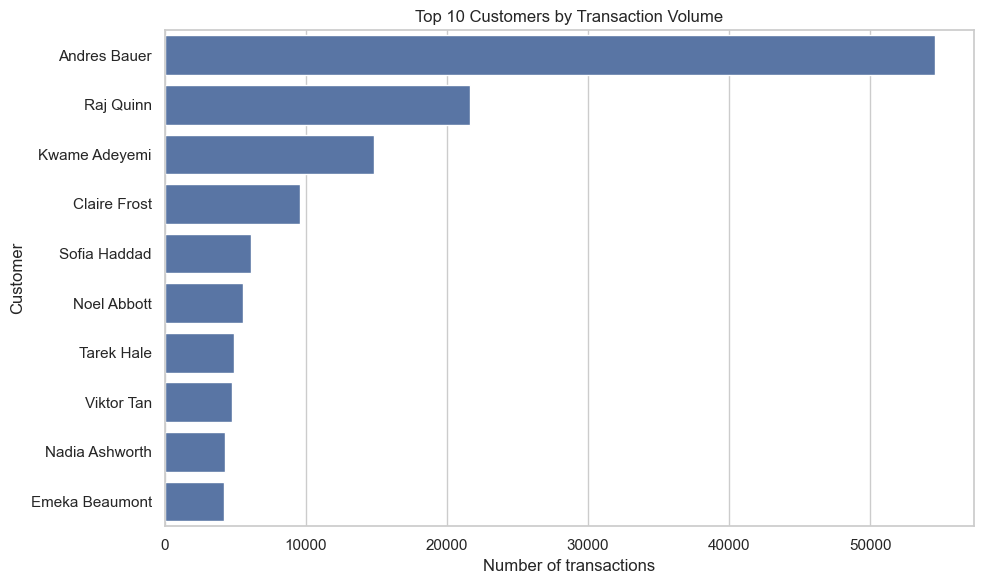

In [61]:
top_customers_viz = (
    customer_transactions
    .sort_values("total_transactions_volume", ascending=False)
    .head(10)
    .merge(
        customers[["customer_id", "first_name", "last_name"]],
        on="customer_id",
        how="left"
    )
)

top_customers_viz["customer"] = (
    top_customers_viz["first_name"] + " " +
    top_customers_viz["last_name"]
)

plt.figure()
sns.barplot(
    data=top_customers_viz,
    x="total_transactions_volume",
    y="customer",
    order=top_customers_viz["customer"]
)
plt.title("Top 10 Customers by Transaction Volume")
plt.xlabel("Number of transactions")
plt.ylabel("Customer")
plt.tight_layout()
plt.show()


## 2. Average transactions per customer by risk band

A fresh customer-level table is created from the original tables so this chart does not depend on the shape of another analysis dataframe.


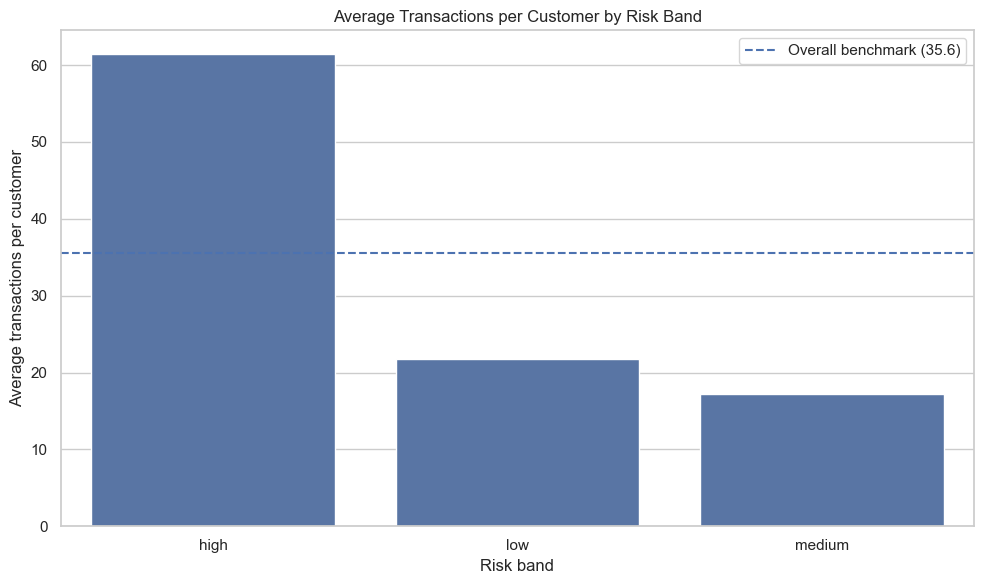

In [62]:
customer_risk_viz = (
    customers[["customer_id", "risk_band"]]
    .merge(
        accounts[["account_id", "customer_id"]],
        on="customer_id",
        how="left"
    )
    .merge(
        transactions[["account_id", "transaction_id"]],
        on="account_id",
        how="left"
    )
    .groupby(["customer_id", "risk_band"], dropna=False)
    .agg(transaction_volume=("transaction_id", "count"))
    .reset_index()
)

risk_summary_viz = (
    customer_risk_viz
    .dropna(subset=["risk_band"])
    .groupby("risk_band")
    .agg(
        average_transactions_per_customer=("transaction_volume", "mean")
    )
    .reset_index()
)

overall_benchmark_viz = customer_risk_viz["transaction_volume"].mean()

plt.figure()
sns.barplot(
    data=risk_summary_viz,
    x="risk_band",
    y="average_transactions_per_customer"
)
plt.axhline(
    overall_benchmark_viz,
    linestyle="--",
    label=f"Overall benchmark ({overall_benchmark_viz:.1f})"
)
plt.title("Average Transactions per Customer by Risk Band")
plt.xlabel("Risk band")
plt.ylabel("Average transactions per customer")
plt.legend()
plt.tight_layout()
plt.show()


## 3. Transaction volume by account type


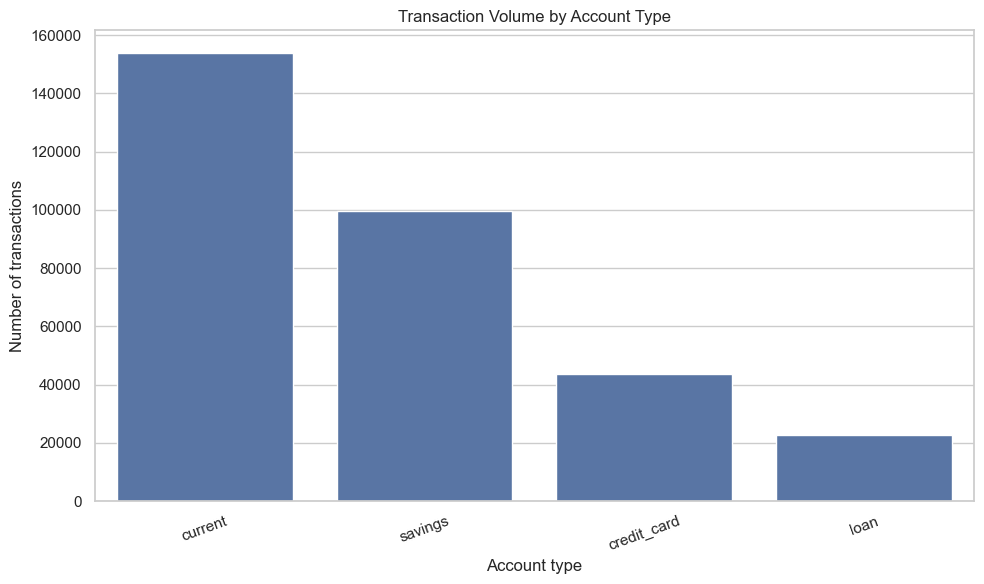

In [63]:
account_type_viz = (
    accounts[["account_id", "account_type"]]
    .merge(
        transactions[["account_id", "transaction_id"]],
        on="account_id",
        how="left"
    )
    .groupby("account_type")
    .agg(transaction_volume=("transaction_id", "count"))
    .reset_index()
    .sort_values("transaction_volume", ascending=False)
)

plt.figure()
sns.barplot(
    data=account_type_viz,
    x="account_type",
    y="transaction_volume"
)
plt.title("Transaction Volume by Account Type")
plt.xlabel("Account type")
plt.ylabel("Number of transactions")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 4. Monthly transaction volume

A line chart is used because chronological order matters.


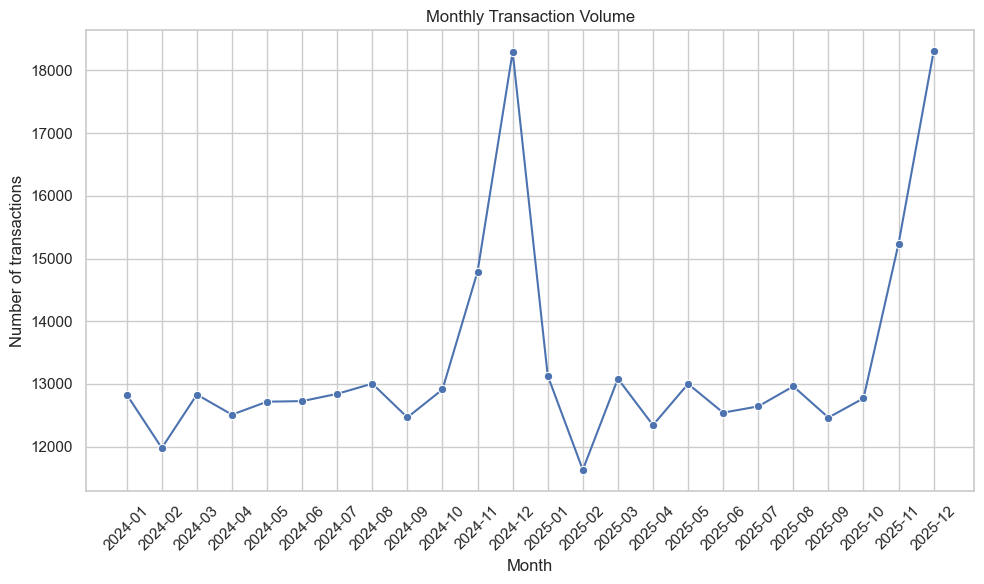

In [64]:
monthly_volume_viz = (
    transactions
    .groupby("month")
    .agg(transaction_volume=("transaction_id", "count"))
    .reset_index()
)

monthly_volume_viz["month"] = monthly_volume_viz["month"].astype(str)

plt.figure()
sns.lineplot(
    data=monthly_volume_viz,
    x="month",
    y="transaction_volume",
    marker="o"
)
plt.title("Monthly Transaction Volume")
plt.xlabel("Month")
plt.ylabel("Number of transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 5. Monthly transaction value and 3-month rolling average

The rolling average smooths short-term fluctuations and makes the broader trend easier to see.


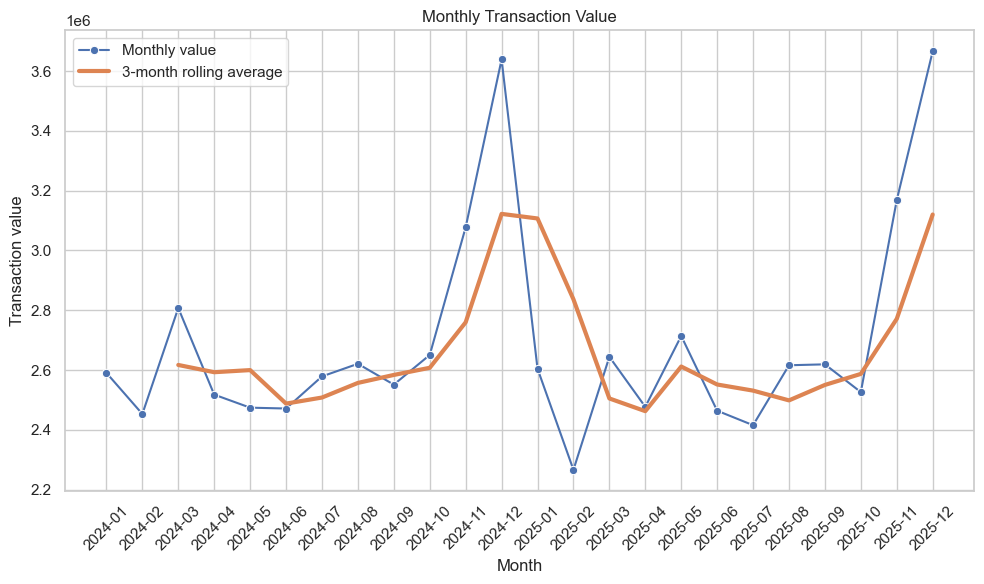

In [65]:
monthly_value_viz = (
    transactions
    .groupby("month")
    .agg(total_transaction_value=("amount", "sum"))
    .reset_index()
)

monthly_value_viz["month"] = monthly_value_viz["month"].astype(str)
monthly_value_viz["rolling_3_month"] = (
    monthly_value_viz["total_transaction_value"]
    .rolling(3)
    .mean()
)

plt.figure()
sns.lineplot(
    data=monthly_value_viz,
    x="month",
    y="total_transaction_value",
    marker="o",
    label="Monthly value"
)
sns.lineplot(
    data=monthly_value_viz,
    x="month",
    y="rolling_3_month",
    linewidth=3,
    label="3-month rolling average"
)
plt.title("Monthly Transaction Value")
plt.xlabel("Month")
plt.ylabel("Transaction value")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


## 6. Transaction volume by channel


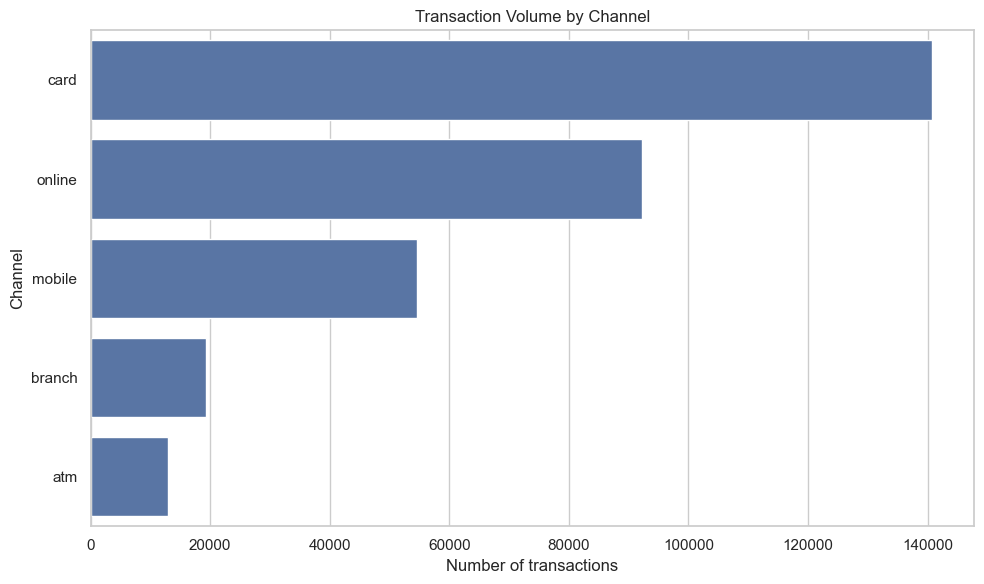

In [66]:
channel_viz = (
    transactions
    .groupby("channel")
    .agg(transaction_volume=("transaction_id", "count"))
    .reset_index()
    .sort_values("transaction_volume", ascending=False)
)

plt.figure()
sns.barplot(
    data=channel_viz,
    x="transaction_volume",
    y="channel",
    order=channel_viz["channel"]
)
plt.title("Transaction Volume by Channel")
plt.xlabel("Number of transactions")
plt.ylabel("Channel")
plt.tight_layout()
plt.show()


## 7. Transaction volume by day of week


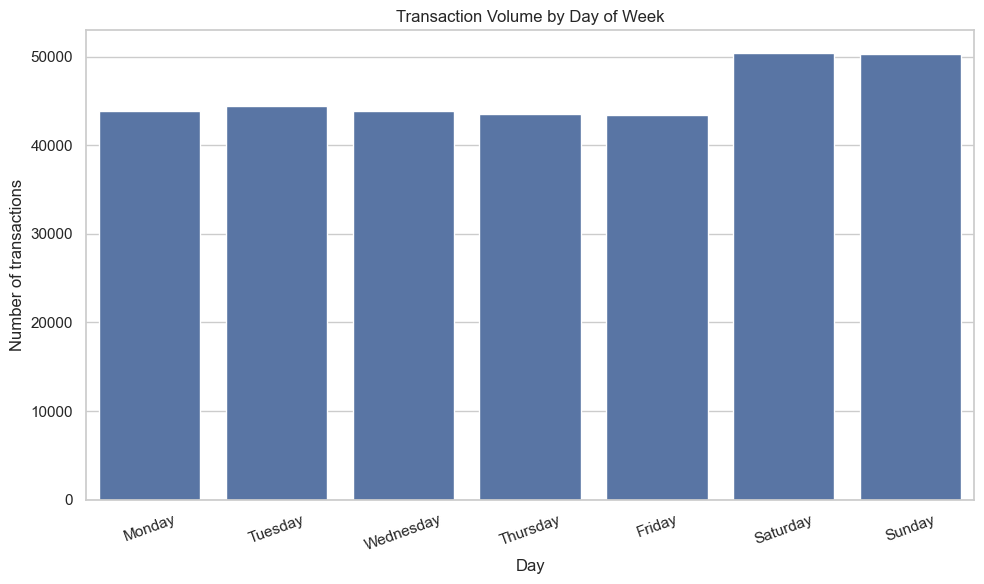

In [67]:
daily_viz = (
    transactions
    .groupby("day_of_week")
    .agg(transaction_volume=("transaction_id", "count"))
    .reset_index()
)

days_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

daily_viz["day_of_week"] = pd.Categorical(
    daily_viz["day_of_week"],
    categories=days_order,
    ordered=True
)

daily_viz = daily_viz.sort_values("day_of_week")

plt.figure()
sns.barplot(
    data=daily_viz,
    x="day_of_week",
    y="transaction_volume"
)
plt.title("Transaction Volume by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of transactions")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 8. Number of accounts vs transaction volume

This uses the existing `customers_accounts` dataframe from the statistical analysis and visualises the very strong relationship found earlier.


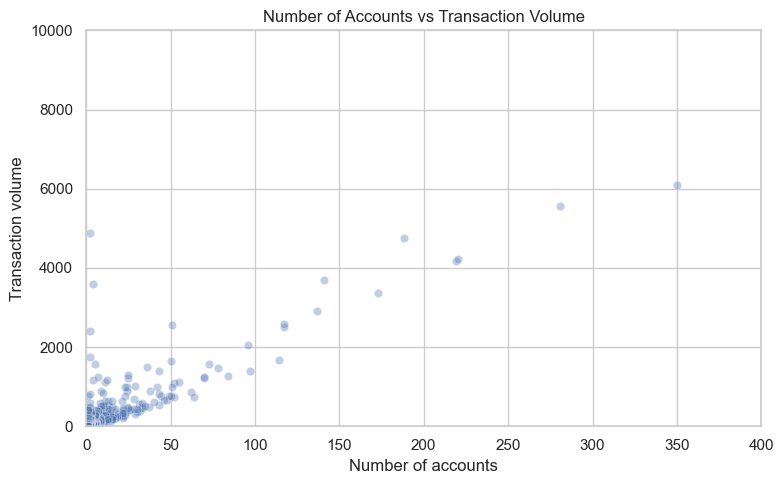

Pearson correlation (all customers): 0.984


In [68]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=customers_accounts,
    x="account_count",
    y="total_transactions_volume",
    alpha=0.35
)

plt.xlim(0, 400)
plt.ylim(0, 10_000)

plt.title("Number of Accounts vs Transaction Volume")
plt.xlabel("Number of accounts")
plt.ylabel("Transaction volume")
plt.tight_layout()
plt.show()

# Correlation is still calculated using ALL customers but there are very few accounts beyond 400 and transactions beyond 10000 therefore we limit our graph for a cleaner look
account_transaction_corr = customers_accounts[
    ["account_count", "total_transactions_volume"]
].corr().iloc[0, 1]

print(f"Pearson correlation (all customers): {account_transaction_corr:.3f}")
